<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

**Worker: [vgi-asn1](https://github.com/Query-farm/vgi-asn1)**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-asn1/blob/main/notebooks/02_nodes_paths_and_unknown_identifiers.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-asn1/blob/main/notebooks/README.md)

# 02 · Structure and names answer different questions

**How do we locate a field without pretending its identifier is recognized?**
We inspect one ASN.1 packet through a tag tree, a text dump and path selection,
then join the observed OIDs to the worker's bundled registry. An unknown identifier
remains an observed value even when it has no friendly name.

## Include an unknown identifier

`INCLUDE_UNKNOWN=True` adds a second authored packet whose OID is absent from the
bundled registry. The experiment sets it to false. The known packet and its
structure stay fixed; only the identifier population changes.

In [1]:
INCLUDE_UNKNOWN = True

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.6":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.6"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, prepare, theme, prose
from IPython.display import display

check_runtime()
prepare("asn1")
import asn1_example as example  # noqa: E402

session = connect(globals())
theme()
if type(INCLUDE_UNKNOWN) is not bool:
    raise ValueError("INCLUDE_UNKNOWN must be a boolean.")

## Attach the released parser

The literal location downloads and verifies the native v0.4.0 release, then caches
it. No compiler or source checkout is needed. Parsing uses only the authored local
inputs below. These structural results do not verify a signature or authenticate data.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'asn1' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-asn1@v0.4.0');

,Success


## Retain complete bytes before projecting fields

The first packet contains INTEGER 5, OID 1.2.840.113549.1.1.11 and UTF8String `hi`.
The second contains only the invented OID 1.2.3.4.5. Both are authored teaching
packets. An algorithm-looking name inside arbitrary bytes does not establish that
an algorithm was used.

In [5]:
%%sql
CREATE TABLE packets AS
SELECT id,label,from_hex(hex_text) AS payload FROM (VALUES
 (1,'Known OID packet','301202010506092a864886f70d01010b0c026869'),
 (2,'Unknown OID packet','300606042a030405')
) t(id,label,hex_text) WHERE id=1 OR {{INCLUDE_UNKNOWN}};
SELECT id,label,hex(payload) AS bytes,asn1.main.decode(payload) AS decoded FROM packets ORDER BY id;

,id,label,bytes,decoded
0,1,Known OID packet,301202010506092A864886F70D01010B0C026869,"[5,""1.2.840.113549.1.1.11"",""hi""]"
1,2,Unknown OID packet,300606042A030405,"[""1.2.3.4.5""]"


## Compare a typed tree with a diagnostic trace

`to_json` retains the root tag and child tags around the values. `dump` expresses
the same packet as offsets, header lengths and content lengths. These are two
inspection views of one input; neither is a new packet nor a decoded certificate.

In [6]:
%%sql
SELECT asn1.main.to_json(payload)::JSON ->> 'tag_name' AS root_tag,
 json_array_length(asn1.main.to_json(payload)::JSON -> 'value') AS child_count,
 asn1.main.to_json(payload)::JSON -> 'value' AS typed_children
FROM packets WHERE id=1;

,root_tag,child_count,typed_children
0,SEQUENCE,3,"[{""class"":""universal"",""constructed"":false,""tag..."


In [7]:
%%sql trace <<
SELECT asn1.main.dump(payload) AS diagnostic_trace FROM packets WHERE id=1;

In [8]:
print(trace.diagnostic_trace.iloc[0])

    0:d=0 hl=2 l=  18 cons: SEQUENCE
    2:d=1 hl=2 l=   1 prim: INTEGER:5
    5:d=1 hl=2 l=   9 prim: OBJECT IDENTIFIER:1.2.840.113549.1.1.11 (sha256WithRSAEncryption)
   16:d=1 hl=2 l=   2 prim: UTF8String:hi


The trace places child headers at byte offsets 2, 5 and 16 inside the 20-byte
packet. Its root has two header bytes and eighteen content bytes. The three child
encodings occupy those same eighteen content bytes; counting the root and all
children as disjoint byte ranges would double-count data.

In [9]:
%%sql nodes <<
SELECT n.path,n.tag_name AS tag,n.constructed,n.header_len AS header_bytes,
 n.len AS content_bytes,n.value AS scalar_value
FROM (SELECT unnest(asn1.main.tlv(payload)) AS n FROM packets WHERE id=1)
ORDER BY n.path;

In [10]:
display(nodes)

,path,tag,constructed,header_bytes,content_bytes,scalar_value
0,$,SEQUENCE,True,2,18,null
1,$.0,INTEGER,False,2,1,5
2,$.1,OBJECT IDENTIFIER,False,2,9,"""1.2.840.113549.1.1.11"""
3,$.2,UTF8String,False,2,2,"""hi"""


## Use discovered paths to retrieve values

`at_path` returns the decoded value at each path reported by `tlv`. The container
path returns its child values, while primitive paths return one value. The explicit
missing path produces JSON `null`, represented as a non-NULL JSON-text result in
this worker; it must not be confused with a successful field lookup.

In [11]:
%%sql
WITH paths AS (
 SELECT n.path FROM (SELECT unnest(asn1.main.tlv(payload)) AS n FROM packets WHERE id=1)
 UNION ALL SELECT '$.99'
)
SELECT path,asn1.main.at_path(payload,path) AS decoded_value,
 json_type(asn1.main.at_path(payload,path)::JSON) AS json_kind,
 asn1.main.at_path(payload,path) IS NULL AS sql_null
FROM packets CROSS JOIN paths WHERE id=1 ORDER BY path;

,path,decoded_value,json_kind,sql_null
0,$,"[5,""1.2.840.113549.1.1.11"",""hi""]",ARRAY,False
1,$.0,5,UBIGINT,False
2,$.1,"""1.2.840.113549.1.1.11""",VARCHAR,False
3,$.2,"""hi""",VARCHAR,False
4,$.99,null,NULL,False


## Preserve the unknown side of a registry join

`oids` provides each identifier and its packet path. A left join to `oid_registry`
adds names without removing unknown rows. Compare the scalar `oid_name` lookup
with that table, then use `oid` to resolve recognized names back to dotted values.
The name comes from this bundled registry; absence is not evidence of malformed
ASN.1 or an unsafe object.

In [12]:
%%sql inventory <<
CREATE TABLE oid_inventory AS
SELECT id,label,o.path,o.oid,o.name AS embedded_name
FROM (SELECT id,label,unnest(asn1.main.oids(payload)) AS o FROM packets);
SELECT i.*,r.name AS registry_name,asn1.main.oid_name(i.oid) AS lookup_name,
 asn1.main.oid(r.name) AS resolved_back
FROM oid_inventory i LEFT JOIN asn1.main.oid_registry r ON i.oid=r.oid ORDER BY id;

In [13]:
display(inventory)
known = inventory.registry_name.notna()
assert (inventory.loc[known, "lookup_name"] == inventory.loc[known, "registry_name"]).all()
assert (inventory.loc[known, "resolved_back"] == inventory.loc[known, "oid"]).all()
assert inventory.loc[~known, "lookup_name"].isna().all()
prose(
    f"**{int(known.sum())} recognized OID occurrence(s)** and **{int((~known).sum())} unknown occurrence(s)** survive the join. The known name resolves back to the observed dotted identifier."
)

,id,label,path,oid,embedded_name,registry_name,lookup_name,resolved_back
0,1,Known OID packet,$.1,1.2.840.113549.1.1.11,sha256WithRSAEncryption,sha256WithRSAEncryption,sha256WithRSAEncryption,1.2.840.113549.1.1.11
1,2,Unknown OID packet,$.0,1.2.3.4.5,None,None,None,None


**1 recognized OID occurrence(s)** and **1 unknown occurrence(s)** survive the join. The known name resolves back to the observed dotted identifier.

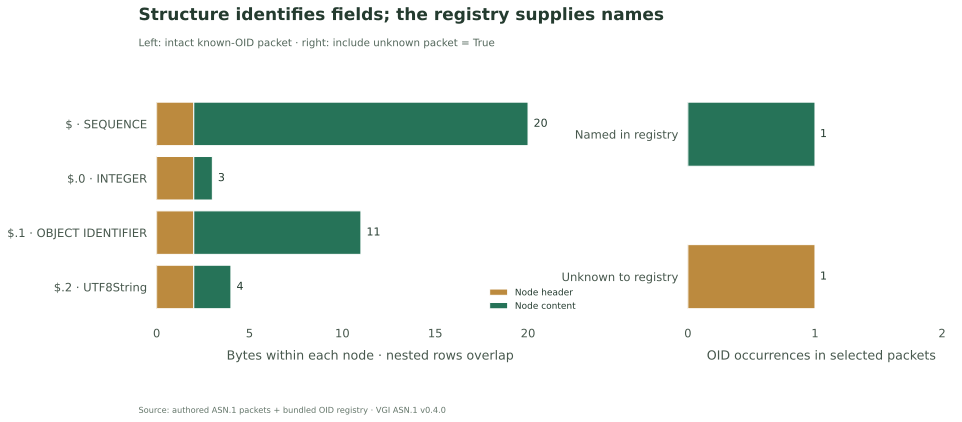

In [14]:
example.plot_inspection(nodes, inventory, INCLUDE_UNKNOWN)

## Experiment · remove only the unknown packet

Set `INCLUDE_UNKNOWN=False`, restart and run all. The unknown count drops from one
to zero while the known packet's tree, paths, dump, name and dotted identifier stay
unchanged. Reset to true. A registry describes the names it knows; preserve source
identifiers when applying it to a broader population.

In [15]:
session.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-asn1](https://github.com/Query-farm/vgi-asn1)
